# Solution: Mini-Project 2 — Student Performance Analysis

**Dataset:** `student_performance.csv` (one semester of results for CSE sections A and B)
**Objective:** understand which factors affect academic performance, and identify students who need support.

**Deliverable:** this notebook, completed. Each task needs code, its output and a short markdown explanation.
It must run top to bottom. Finish with an *Insights & Recommendations* section.

**Rules used in this project**
- A subject is **passed** with 40 or more marks out of 100. An absent subject (missing mark) counts as **not passed**.
- A student **passes overall** only if all five subjects are passed.
- The minimum attendance requirement is **75%**.

**Student name:** _____________ &nbsp;&nbsp; **Roll no.:** _____________ &nbsp;&nbsp; **Section:** ___

> **Instructor solution.** Attempt the exercises yourself before reading this. Your answers may differ in method and still be correct.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "../../datasets/"
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4.5)
pd.set_option("display.float_format", "{:,.2f}".format)

SUBJECTS = ["Mathematics", "Physics", "Programming", "English", "Electronics"]
PASS_MARK = 40

## A. Data preparation

### Exercise 1 — Load and inspect

Load the data. Report its shape and data types, and list every data-quality problem you find (think about duplicates, inconsistent categories, impossible values and missing values).

In [2]:
raw = pd.read_csv(DATA_DIR + "student_performance.csv")
print("Shape:", raw.shape)
raw.info()
print("\nDuplicate rows:", raw.duplicated().sum())
print("Gender labels:", raw["Gender"].unique())
print("\nMissing values:\n", raw.isna().sum()[raw.isna().sum() > 0])
display(raw[["Attendance_Pct"] + SUBJECTS].describe().T[["min", "max"]])

Shape: (246, 13)
<class 'pandas.DataFrame'>
RangeIndex: 246 entries, 0 to 245
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Student_ID            246 non-null    str    
 1   Section               246 non-null    str    
 2   Gender                246 non-null    str    
 3   Accommodation         246 non-null    str    
 4   Internet_Access       246 non-null    str    
 5   Attendance_Pct        246 non-null    float64
 6   Study_Hours_Per_Week  241 non-null    float64
 7   Previous_GPA          246 non-null    float64
 8   Mathematics           242 non-null    float64
 9   Physics               242 non-null    float64
 10  Programming           241 non-null    float64
 11  English               242 non-null    float64
 12  Electronics           242 non-null    float64
dtypes: float64(8), str(5)
memory usage: 25.1 KB

Duplicate rows: 6
Gender labels: <StringArray>
['Female', 'Male', 'M', 'ma

,min,max
Attendance_Pct,-5.00,112.50
Mathematics,-1.00,150.00
Physics,36.00,98.00
Programming,34.00,100.00
English,42.00,92.00
Electronics,11.00,97.00


### Exercise 2 — Clean the data

Remove duplicates, standardise `Gender`, and set impossible attendance and marks to `NaN`. Do **not** fill missing marks: a missing mark means the student was absent, and that is real information. Fill missing `Study_Hours_Per_Week` with the median and explain why.

In [3]:
df = raw.drop_duplicates().reset_index(drop=True)
print("Students after removing duplicates:", len(df), "| unique IDs:", df["Student_ID"].nunique())

df["Gender"] = df["Gender"].str.strip().str.lower().map({"m": "Male", "male": "Male", "f": "Female", "female": "Female"})

for col in ["Attendance_Pct"] + SUBJECTS:
    bad = ~df[col].between(0, 100) & df[col].notna()
    if bad.any():
        print(f"{col}: {bad.sum()} impossible value(s) -> NaN: {df.loc[bad, col].tolist()}")
    df[col] = df[col].where(~bad)

df["Study_Hours_Per_Week"] = df["Study_Hours_Per_Week"].fillna(df["Study_Hours_Per_Week"].median())
print("\nRemaining missing:\n", df.isna().sum()[df.isna().sum() > 0])

Students after removing duplicates: 240 | unique IDs: 240
Attendance_Pct: 3 impossible value(s) -> NaN: [112.5, 104.0, -5.0]
Mathematics: 2 impossible value(s) -> NaN: [-1.0, 150.0]

Remaining missing:
 Attendance_Pct    3
Mathematics       6
Physics           4
Programming       4
English           4
Electronics       4
dtype: int64


> **Note:** Missing study hours are filled with the median because they are a minor input to the analysis and the median is not pulled by extreme values. Missing marks are **not** filled. Inventing a mark would hide an absence. Impossible marks (−1, 150) become missing; in a real setting you would check them with the exam cell.

## B. Subject-wise analysis

### Exercise 3 — Subject-wise averages

For each subject, calculate the mean, median, standard deviation, minimum, maximum and number absent. Plot the mean of each subject for Section A and Section B side by side. Which subject is hardest?

,mean,median,std,min,max,absent
Electronics,58.60,59.00,13.10,11.00,97.00,4
Mathematics,60.60,60.00,12.30,29.00,100.00,6
Physics,63.80,64.00,11.80,36.00,98.00,4
Programming,66.10,66.00,12.30,34.00,100.00,4
English,71.60,72.00,8.50,42.00,92.00,4


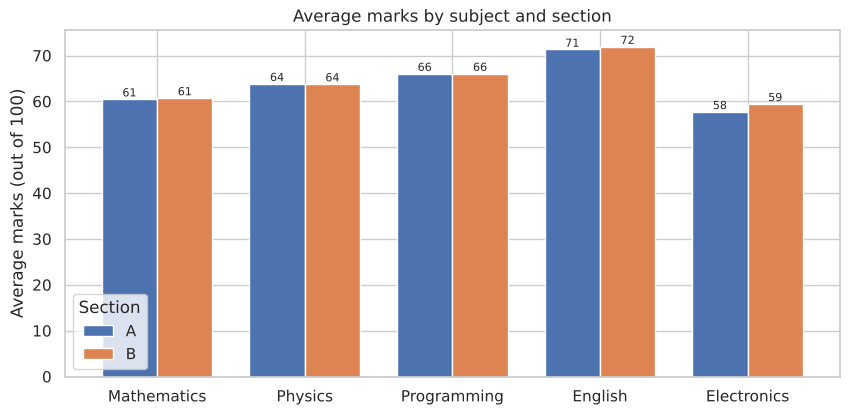

Hardest subject (lowest mean): Electronics


In [4]:
stats = df[SUBJECTS].agg(["mean", "median", "std", "min", "max"]).T
stats["absent"] = df[SUBJECTS].isna().sum()
display(stats.sort_values("mean").round(1))

sec = df.groupby("Section")[SUBJECTS].mean().T
ax = sec.plot(kind="bar", figsize=(10, 4.5), width=0.75)
ax.set(title="Average marks by subject and section", xlabel="", ylabel="Average marks (out of 100)")
ax.legend(title="Section")
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8)
plt.xticks(rotation=0)
plt.show()
print("Hardest subject (lowest mean):", stats["mean"].idxmin())

### Exercise 4 — Student totals, percentage and result

For each student, compute `Total` (out of 500, counting an absent subject as 0), `Percentage`, `Subjects_Passed` and `Result` (`Pass` / `Fail`).

In [5]:
df["Total"] = df[SUBJECTS].fillna(0).sum(axis=1)
df["Percentage"] = df["Total"] / (100 * len(SUBJECTS)) * 100
df["Subjects_Passed"] = (df[SUBJECTS] >= PASS_MARK).sum(axis=1)       # NaN >= 40 is False, so absent = not passed
df["Result"] = np.where(df["Subjects_Passed"] == len(SUBJECTS), "Pass", "Fail")
df[["Student_ID", "Section", "Total", "Percentage", "Subjects_Passed", "Result"]].head(8)

,Student_ID,Section,Total,Percentage,Subjects_Passed,Result
0,CSEA001,A,267.00,53.40,5,Pass
1,CSEA002,A,190.00,38.00,2,Fail
2,CSEA003,A,354.00,70.80,5,Pass
3,CSEA004,A,280.00,56.00,5,Pass
4,CSEA005,A,311.00,62.20,5,Pass
5,CSEA006,A,390.00,78.00,5,Pass
6,CSEA007,A,372.00,74.40,5,Pass
7,CSEA008,A,326.00,65.20,5,Pass


## C. Pass / fail analysis

### Exercise 5 — Pass rates

Report (a) the pass rate in each subject, (b) the overall pass rate, and (c) the overall pass rate by Section, Gender, Accommodation and Internet_Access. Show (a) as a bar chart with a reference line at the overall pass rate.

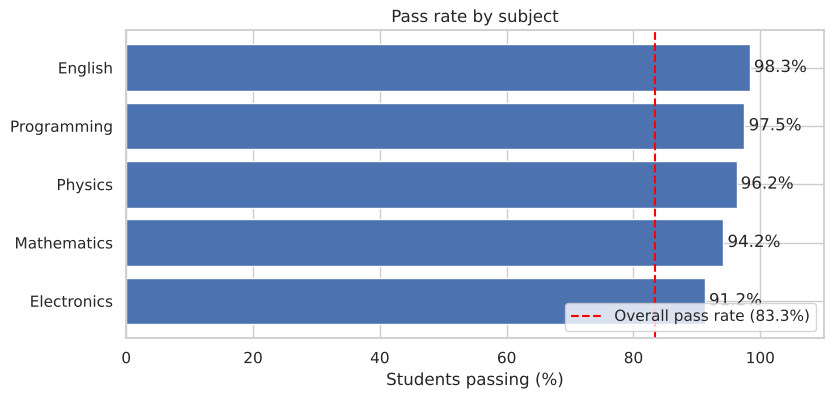

Section
A   82.50
B   84.20

Gender
Female   86.00
Male     81.60

Accommodation
Day Scholar   86.20
Hosteller     80.00

Internet_Access
No    90.50
Yes   81.80



In [6]:
subj_pass = ((df[SUBJECTS] >= PASS_MARK).mean() * 100).sort_values()
overall = (df["Result"] == "Pass").mean() * 100

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(subj_pass.index, subj_pass.values)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.axvline(overall, color="red", linestyle="--", label=f"Overall pass rate ({overall:.1f}%)")
ax.set(title="Pass rate by subject", xlabel="Students passing (%)", xlim=(0, 110))
ax.legend(loc="lower right")
plt.show()

for col in ["Section", "Gender", "Accommodation", "Internet_Access"]:
    print((df.groupby(col)["Result"].apply(lambda s: (s == "Pass").mean() * 100)).round(1).to_string(), end="\n\n")

> **Note:** The overall pass rate is well below every single-subject pass rate. A student has to clear **all five** subjects, so failures in different subjects add up.

### Exercise 6 — How many subjects do failing students fail?

For students who failed, how many subjects did they fail? Show the counts. What does this mean for the kind of support they need?

In [7]:
failed = df[df["Result"] == "Fail"]
backlogs = (len(SUBJECTS) - failed["Subjects_Passed"]).value_counts().sort_index()
backlogs.index.name = "Subjects not passed"
display(backlogs.to_frame("Students"))
print(f"{backlogs.get(1, 0) / len(failed) * 100:.0f}% of failing students missed only one subject")

,Students
Subjects not passed,
1,31
2,6
3,1
4,2


78% of failing students missed only one subject


## D. Attendance and marks

### Exercise 7 — Correlation between attendance and marks

(a) Compute the correlation of `Attendance_Pct`, `Study_Hours_Per_Week` and `Previous_GPA` with `Percentage`. (b) Draw a scatter plot of attendance vs percentage with a regression line and a vertical line at 75%. (c) Group students into attendance bands (<65, 65–75, 75–85, ≥85) and compare average percentage and pass rate.

Correlation with Percentage:
 Attendance_Pct         0.60
Study_Hours_Per_Week   0.34
Previous_GPA           0.57
Name: Percentage, dtype: float64



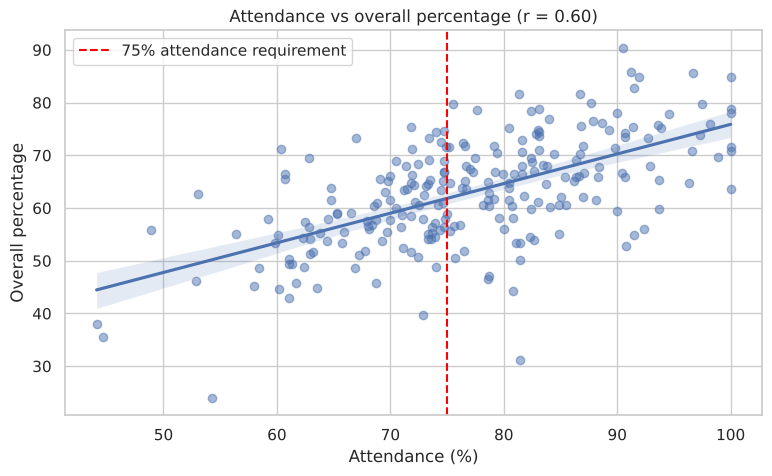

,Students,Avg_Percentage,Pass_Rate
Attendance_Band,,,
<65%,35,52.70,57.10
65-75%,74,60.60,85.10
75-85%,73,64.10,84.90
85%+,55,71.30,94.50


In [8]:
corr = df[["Attendance_Pct", "Study_Hours_Per_Week", "Previous_GPA", "Percentage"]].corr()["Percentage"].drop("Percentage")
print("Correlation with Percentage:\n", corr.round(2), end="\n\n")

fig, ax = plt.subplots(figsize=(9, 5))
sns.regplot(data=df, x="Attendance_Pct", y="Percentage", scatter_kws={"alpha": 0.5}, ax=ax)
ax.axvline(75, color="red", linestyle="--", label="75% attendance requirement")
ax.set(title=f"Attendance vs overall percentage (r = {corr['Attendance_Pct']:.2f})",
       xlabel="Attendance (%)", ylabel="Overall percentage")
ax.legend()
plt.show()

df["Attendance_Band"] = pd.cut(df["Attendance_Pct"], bins=[0, 65, 75, 85, 100.01], right=False,
                               labels=["<65%", "65-75%", "75-85%", "85%+"])
band = df.groupby("Attendance_Band", observed=True).agg(
    Students=("Student_ID", "count"),
    Avg_Percentage=("Percentage", "mean"),
    Pass_Rate=("Result", lambda s: (s == "Pass").mean() * 100))
band.round(1)

### Exercise 8 — Correlation heatmap

Draw a heatmap of the correlations between attendance, study hours, previous GPA and all five subjects. Which subjects are most closely linked to each other?

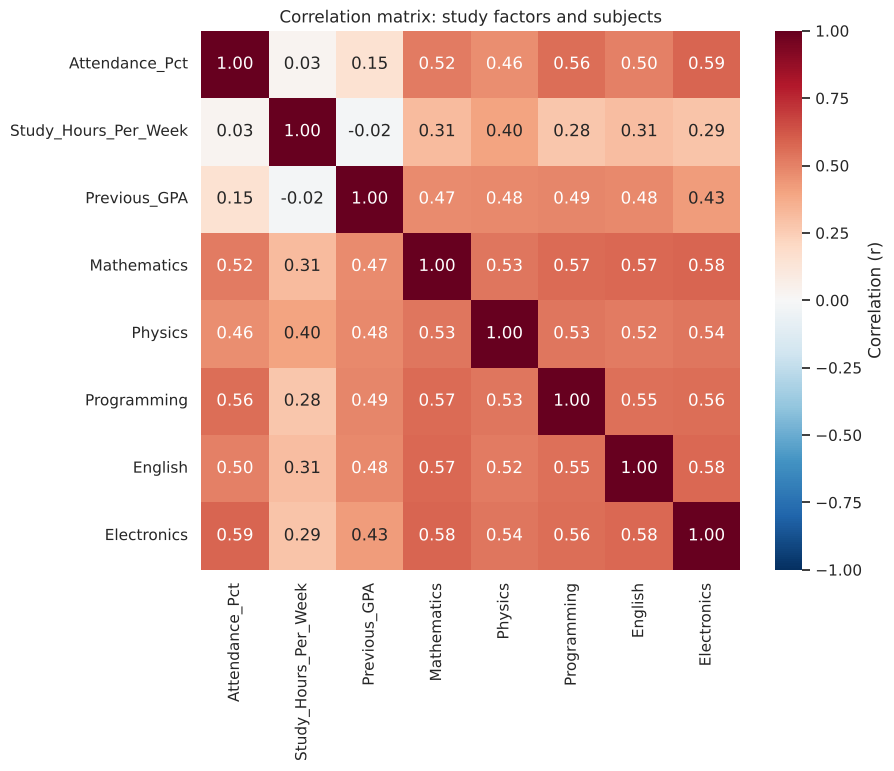

Most closely linked subject pair: ('Mathematics', 'Electronics') (r = 0.58)


In [9]:
cols = ["Attendance_Pct", "Study_Hours_Per_Week", "Previous_GPA"] + SUBJECTS
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Correlation (r)"}, ax=ax)
ax.set_title("Correlation matrix: study factors and subjects")
plt.show()

sc = df[SUBJECTS].corr().where(~np.eye(len(SUBJECTS), dtype=bool)).stack()
print("Most closely linked subject pair:", sc.idxmax(), f"(r = {sc.max():.2f})")

## E. Grade distribution

### Exercise 9 — Grades and distribution plots

Assign a grade from `Percentage`: **O** ≥ 90, **A+** 80–89, **A** 70–79, **B+** 60–69, **B** 50–59, **C** 40–49 and **F** < 40, or `F` whenever the student did not pass overall. Plot (a) a histogram of percentage with a KDE line, split by section, and (b) a count plot of grades by section in grade order.

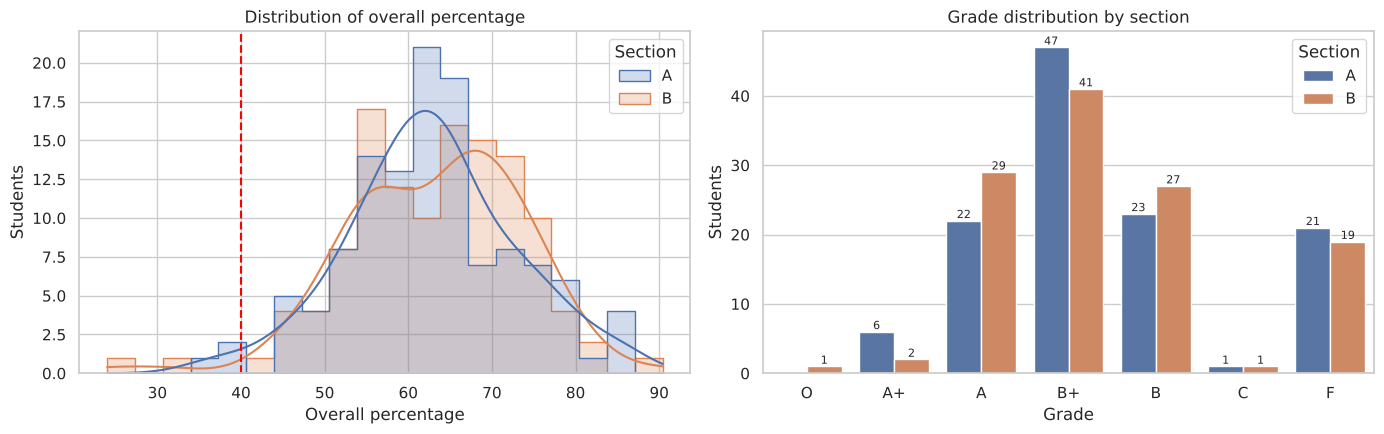

Section,A,B,All
Grade,,,
O,0,1,1
A+,6,2,8
A,22,29,51
B+,47,41,88
B,23,27,50
C,1,1,2
F,21,19,40
All,120,120,240


In [10]:
bins = [0, 40, 50, 60, 70, 80, 90, 100.01]
labels = ["F", "C", "B", "B+", "A", "A+", "O"]
df["Grade"] = pd.cut(df["Percentage"], bins=bins, labels=labels, right=False).astype(str)
df.loc[df["Result"] == "Fail", "Grade"] = "F"
grade_order = ["O", "A+", "A", "B+", "B", "C", "F"]
df["Grade"] = pd.Categorical(df["Grade"], categories=grade_order, ordered=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(data=df, x="Percentage", hue="Section", kde=True, bins=20, element="step", ax=axes[0])
axes[0].axvline(40, color="red", linestyle="--")
axes[0].set(title="Distribution of overall percentage", xlabel="Overall percentage", ylabel="Students")

sns.countplot(data=df, x="Grade", hue="Section", order=grade_order, ax=axes[1])
axes[1].set(title="Grade distribution by section", xlabel="Grade", ylabel="Students")
for c in axes[1].containers:
    axes[1].bar_label(c, fontsize=8)
plt.tight_layout()
plt.show()

pd.crosstab(df["Grade"], df["Section"], margins=True)

## F. Students who need support

### Exercise 10 — Identify at-risk students

List the students who have **attendance below 75% and an overall result of Fail**. How many are there in each section? Sort the list so the most at-risk students come first.

In [11]:
at_risk = (df[(df["Attendance_Pct"] < 75) & (df["Result"] == "Fail")]
           .sort_values(["Subjects_Passed", "Percentage"])
           [["Student_ID", "Section", "Attendance_Pct", "Percentage", "Subjects_Passed", "Grade"]])
print(len(at_risk), "at-risk students;", at_risk["Section"].value_counts().to_dict())
at_risk.head(10)

26 at-risk students; {'B': 13, 'A': 13}


,Student_ID,Section,Attendance_Pct,Percentage,Subjects_Passed,Grade
171,CSEB052,B,54.30,24.00,1,F
116,CSEA117,A,44.70,35.60,1,F
1,CSEA002,A,44.10,38.00,2,F
193,CSEB074,B,60.20,44.60,3,F
164,CSEB045,B,58.00,45.20,3,F
90,CSEA091,A,61.10,49.40,3,F
75,CSEA076,A,72.90,39.80,4,F
141,CSEB022,B,61.10,43.00,4,F
59,CSEA060,A,63.50,44.80,4,F
52,CSEA053,A,68.70,45.80,4,F


## G. Insights & recommendations

### Exercise 11 — Insights and recommendations

Write **at least five insights** backed by numbers and **three recommendations** for the department. State clearly what the data cannot prove.

In [12]:
print(f"Overall pass rate: {overall:.1f}%")
print(f"Hardest subject: {stats['mean'].idxmin()} (mean {stats['mean'].min():.1f}, pass rate {subj_pass.min():.1f}%)")
print(f"Attendance-percentage correlation: r = {corr['Attendance_Pct']:.2f}")
print("Pass rate by attendance band:", band["Pass_Rate"].round(1).to_dict())
print(f"At-risk students: {len(at_risk)}")

Overall pass rate: 83.3%
Hardest subject: Electronics (mean 58.6, pass rate 91.2%)
Attendance-percentage correlation: r = 0.60
Pass rate by attendance band: {'<65%': 57.1, '65-75%': 85.1, '75-85%': 84.9, '85%+': 94.5}
At-risk students: 26


> **Note:** **Sample insights** (check the exact figures against your own output)
1. Electronics and Mathematics have the lowest average marks, so they are the bottleneck subjects.
2. The overall pass rate is much lower than any single-subject pass rate, because a student must clear all five subjects.
3. Attendance has a moderate positive correlation with performance (r ≈ 0.6). The pass rate is lowest (under 60%) for students below 65% attendance and highest (over 90%) for those at 85% or above.
4. Previous GPA is also a strong predictor, so earlier academic history carries forward.
5. Weekly study hours show a weaker link than attendance or previous GPA.

**Recommendations**
1. Run remedial classes in Electronics and Mathematics, starting with students who failed only one subject.
2. Track attendance weekly and contact students who fall below 75% early, not only at the end of the semester.
3. Assign mentors to the at-risk list from Task 10.

**Cannot prove:** that attendance *causes* better marks. Motivated students may simply attend more and also study more.
The data is synthetic and covers one semester only.